# Assignment 2 - Link prediction

Fundamentals of Data Science, Part 1 (technical solution).

We frame link prediction as a binary classification problem: for a pair of nodes (u, v) we predict 1 if the link exists in the original network and 0 if not. The structure of the notebook follows the sections of the report. Parts of the code (loading the edge list, `getFeature`, writing the predictions) are based on the Lab 5 auxiliary notebook.

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import greedy_modularity_communities

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

SEED = 42
np.random.seed(SEED)

## 0. Loading the data

In [2]:
G = nx.read_edgelist('input/edges_train.edgelist', data=False, nodetype=int, delimiter=',')
attributes = pd.read_csv('input/attributes.csv', index_col='ID')['attribute']

# some nodes might have no visible edges, so we add all nodes explicitly
G.add_nodes_from(attributes.index)
attr = attributes.to_dict()
N = G.number_of_nodes()

print('Number of nodes:', N)
print('Number of visible edges:', G.number_of_edges())
print('Average degree: %0.2f' % (2 * G.number_of_edges() / N))
print('Average clustering coefficient: %0.3f' % nx.average_clustering(G))

Number of nodes: 1800
Number of visible edges: 6377
Average degree: 7.09
Average clustering coefficient: 0.109


### Distribution of the attribute groups

The node attribute could be a sensitive feature (e.g. political affiliation), so we first look at how the groups are distributed and how they are connected to each other. This is also relevant for the ethics part.

In [3]:
groups = sorted(attributes.unique())
group_counts = attributes.value_counts().sort_index()
print(group_counts)

attribute
a    300
b    300
c    300
d    300
e    300
f    300
Name: count, dtype: int64


In [4]:
# how often do nodes connect to their own group? (homophily)
mixing = pd.DataFrame(0, index=groups, columns=groups)
for u, v in G.edges:
    mixing.loc[attr[u], attr[v]] += 1
    if attr[u] != attr[v]:
        mixing.loc[attr[v], attr[u]] += 1

# row = group of a node, column = group of its neighbour (as a share of the row)
print(mixing.div(mixing.sum(axis=1), axis=0).round(2))

same_group = np.mean([attr[u] == attr[v] for u, v in G.edges])
print('\nShare of edges within the same group: %0.3f' % same_group)
print('Expected share if links were random:  %0.3f' % ((group_counts / N) ** 2).sum())

      a     b     c     d     e     f
a  0.38  0.12  0.12  0.13  0.13  0.13
b  0.12  0.38  0.14  0.14  0.14  0.08
c  0.11  0.14  0.37  0.10  0.15  0.14
d  0.12  0.14  0.11  0.35  0.11  0.17
e  0.12  0.14  0.16  0.11  0.37  0.12
f  0.12  0.08  0.14  0.17  0.12  0.36

Share of edges within the same group: 0.538
Expected share if links were random:  0.167


The groups have exactly the same size (300 nodes each). More than half of the edges are between nodes of the same group, while only ~17% would be expected if links were formed randomly, so there is strong homophily in the network.

## 1. Feature engineering

Features are computed for a pair of nodes (u, v).:

- **Common neighbours**: social networks have a high clustering coefficient, so two nodes with many common friends are likely to be connected.
- **Jaccard coefficient**: common neighbours divided by the total number of neighbours of u and v, so nodes with a high degree don't automatically get a high score.
- **Adamic-Adar index**: also based on common neighbours, but a common neighbour with a low degree counts more than a 'hub' that is connected to everyone.
- **Preferential attachment**: degree(u) * degree(v), nodes with many links tend to get more links
- **Same community**: 1 if u and v are in the same community. Communities are detected with greedy modularity maximisation.
- **Same attribute**: 1 if u and v belong to the same group (homophily).

The first four are available in NetworkX

In [5]:
FEATURES = ['common_neighbours', 'jaccard', 'adamic_adar', 'pref_attachment',
            'same_community', 'same_attribute']

def get_communities(graph):
    # returns a dict: node -> community number
    communities = greedy_modularity_communities(graph)
    comm = {}
    for k, c in enumerate(communities):
        for node in c:
            comm[node] = k
    return comm

def getFeatures(graph, pairs, comm):
    # computes the features for a list of node pairs on the given graph
    pairs = [(int(u), int(v)) for u, v in pairs]
    df = pd.DataFrame(pairs, columns=['u', 'v'])
    df['common_neighbours'] = [len(list(nx.common_neighbors(graph, u, v))) for u, v in pairs]
    df['jaccard'] = [p for u, v, p in nx.jaccard_coefficient(graph, pairs)]
    df['adamic_adar'] = [p for u, v, p in nx.adamic_adar_index(graph, pairs)]
    df['pref_attachment'] = [p for u, v, p in nx.preferential_attachment(graph, pairs)]
    df['same_community'] = [int(comm[u] == comm[v]) for u, v in pairs]
    df['same_attribute'] = [int(attr[u] == attr[v]) for u, v in pairs]
    return df

def getFeature(graph, i, j, comm):
    return getFeatures(graph, [(i, j)], comm)[FEATURES]

## 2. Data preparation

**Positive examples.** If we would use the visible edges directly as positive examples, the link is still in the graph when computing the features, so the training examples would look different from the test examples.

To avoid this we remove ~10% of the visible edges and use them as positive examples, with the features computed on the network without these edges. To get more training data we repeat this 10 times: the visible edges are split into 10 parts and each part is removed once. In this way every visible edge is used once as a positive example. The communities are also recomputed every time on the reduced network, otherwise the removed edges would still influence the 'same community' feature.

**Negative examples.** Random pairs of nodes that are not connected in the visible network. We sample 5 times more negatives than positives here, so we can test different ratios later (Section 2.2). For the main dataset we use a 1:1 ratio.

In [6]:
def sample_negatives(graph, k, used):
    # k random node pairs that are not connected in graph (and not sampled before)
    neg = []
    while len(neg) < k:
        i, j = np.random.randint(N, size=2)
        pair = (min(i, j), max(i, j))
        if i != j and not graph.has_edge(i, j) and pair not in used:
            used.add(pair)
            neg.append(pair)
    return neg

def build_dataset(graph, n_parts=10, neg_ratio=1):
    edges = np.array(graph.edges)
    parts = np.array_split(np.random.permutation(len(edges)), n_parts)
    used = set()
    dfs = []
    for idx in parts:
        pos = [tuple(e) for e in edges[idx]]
        H = graph.copy()
        H.remove_edges_from(pos)          # network without the 'hidden' edges
        comm = get_communities(H)
        neg = sample_negatives(graph, len(pos) * neg_ratio, used)
        df = getFeatures(H, pos + neg, comm)
        df['label'] = [1] * len(pos) + [0] * len(neg)
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

all_data = build_dataset(G, neg_ratio=5)   # takes ~1 min because of the community detection
print(all_data['label'].value_counts())

label
0    31885
1     6377
Name: count, dtype: int64


In [7]:
positives = all_data[all_data.label == 1]
negatives = all_data[all_data.label == 0]

# main dataset: 1:1, the other negatives are kept apart for the ratio experiment
neg_main = negatives.sample(len(positives), random_state=SEED)
neg_extra = negatives.drop(neg_main.index)
data = pd.concat([positives, neg_main])

print('Dataset size:', len(data))
print(data.groupby('label')[FEATURES].mean().round(3))

Dataset size: 12754
       common_neighbours  jaccard  adamic_adar  pref_attachment  \
label                                                             
0                  0.040    0.003        0.014           39.685   
1                  0.577    0.028        0.257          112.403   

       same_community  same_attribute  
label                                  
0               0.166           0.167  
1               0.868           0.538  


The mean feature values already show a clear difference between links and non-links, especially for common neighbours and same community.

### 2.1 Train, validation and test set

We split the data into 70% training, 15% validation and 15% test (stratified, so every set is 50/50 like the final test data). The hyperparameters are tuned with 5-fold cross-validation on the training set, the models are compared on the validation set and the test set is only used once at the end for the selected model.

In [8]:
train, rest = train_test_split(data, test_size=0.3, stratify=data['label'], random_state=SEED)
val, test = train_test_split(rest, test_size=0.5, stratify=rest['label'], random_state=SEED)

X_train, y_train = train[FEATURES], train['label']
X_val, y_val = val[FEATURES], val['label']
X_test, y_test = test[FEATURES], test['label']

print('train: %d, validation: %d, test: %d' % (len(train), len(val), len(test)))

train: 8927, validation: 1913, test: 1914


In [9]:
pos_train = train[train.label == 1]
neg_train = train[train.label == 0]

results = []
for ratio in [1, 2, 3, 5]:
    n_extra = len(pos_train) * ratio - len(neg_train)
    tr = pd.concat([pos_train, neg_train, neg_extra.sample(max(n_extra, 0), random_state=SEED)])
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    model.fit(tr[FEATURES], tr['label'])
    pred = model.predict(X_val)
    results.append([ratio, accuracy_score(y_val, pred), recall_score(y_val, pred), pred.mean()])

pd.DataFrame(results, columns=['neg:pos ratio', 'val accuracy', 'TPR', 'share predicted as link']).round(3)

/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/

,neg:pos ratio,val accuracy,TPR,share predicted as link
0,1,0.864,0.888,0.524
1,2,0.862,0.883,0.521
2,3,0.819,0.748,0.429
3,5,0.710,0.450,0.239


With more negatives the model predicts 'no link' more often (the TPR drops a lot), which lowers the accuracy on balanced data. Ratio 1:1 and 2:1 are about the same, so we keep 1:1 because it matches the distribution of the final test set.

## 3. Model selection

We compare four classifiers: logistic regression, k-NN, a decision tree and a random forest. For logistic regression and k-NN the features are standardised first, because k-NN uses distances and the features have very different scales (e.g. preferential attachment vs. Jaccard). Trees don't need this.

## 4. Model training and validation

For each model the hyperparameters are selected with a grid search with 5-fold cross-validation on the training set:
- Logistic regression: C (inverse of the regularisation strength)
- k-NN: number of neighbours K
- Decision tree: max depth and minimum samples per leaf (to prevent overfitting)
- Random forest: max depth and number of features per split (`None` = all features, which is the same as bagging)

In [10]:
models = {
    'Logistic regression': (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                            {'logisticregression__C': [0.01, 0.1, 1, 10, 100]}),
    'k-NN': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
             {'kneighborsclassifier__n_neighbors': [5, 15, 31, 51, 101]}),
    'Decision tree': (DecisionTreeClassifier(random_state=SEED),
                      {'max_depth': [2, 3, 4, 6, 8, 12], 'min_samples_leaf': [1, 10, 50]}),
    'Random forest': (RandomForestClassifier(n_estimators=200, random_state=SEED),
                      {'max_depth': [4, 6, 10, None], 'max_features': ['sqrt', None]}),
}

best_models = {}
results = []
for name, (model, params) in models.items():
    grid = GridSearchCV(model, params, cv=5, scoring='accuracy')
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_

    val_pred = grid.predict(X_val)
    val_prob = grid.predict_proba(X_val)[:, 1]
    results.append([name, grid.best_params_, grid.best_score_,
                    accuracy_score(y_val, val_pred), roc_auc_score(y_val, val_prob)])
    print(name, 'done')

pd.DataFrame(results, columns=['model', 'best parameters', 'CV accuracy', 'val accuracy', 'val AUC']).round(3)

Logistic regression done


/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/

k-NN done
Decision tree done
Random forest done


,model,best parameters,CV accuracy,val accuracy,val AUC
0,Logistic regression,{'logisticregression__C': 1},0.849,0.864,0.911
1,k-NN,{'kneighborsclassifier__n_neighbors': 31},0.849,0.864,0.913
2,Decision tree,"{'max_depth': 6, 'min_samples_leaf': 10}",0.849,0.864,0.915
3,Random forest,"{'max_depth': 6, 'max_features': 'sqrt'}",0.851,0.866,0.919


/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


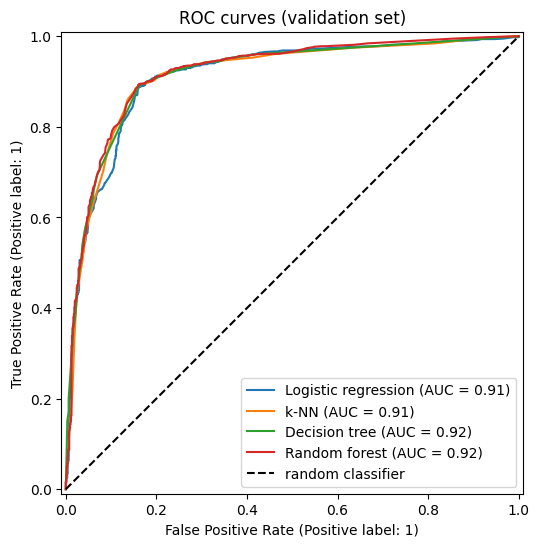

In [11]:
# ROC curves of the four models on the validation set
fig, ax = plt.subplots(figsize=(6, 6))
for name, model in best_models.items():
    RocCurveDisplay.from_estimator(model, X_val, y_val, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label='random classifier')
ax.legend()
plt.title('ROC curves (validation set)')
plt.show()

All four models have almost the same accuracy and AUC on the validation set (around 0.86 accuracy), so a more complex model does not really improve the performance here. We chose **logistic regression** as our final model, because:
- the performance is the same as the other models
- it is the easiest model to interpret: every feature gets one coefficient, so we can see (and explain) what the model bases its predictions on
- it gives a probability for every link, so the threshold (default 0.5) could be changed if needed

The coefficients are shown below (the features are standardised, so the coefficients can be compared with each other).

common_neighbours   -0.526
jaccard              0.034
same_attribute       0.197
pref_attachment      0.957
adamic_adar          1.375
same_community       1.476
dtype: float64


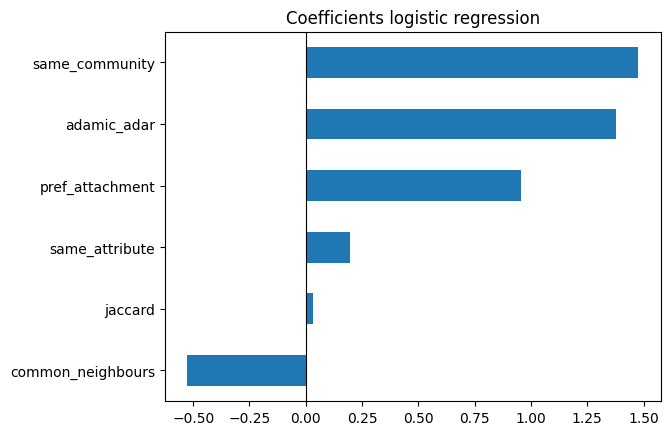

In [12]:
final_model = best_models['Logistic regression']
coefs = pd.Series(final_model[-1].coef_[0], index=FEATURES).sort_values()
print(coefs.round(3))

coefs.plot.barh(title='Coefficients logistic regression')
plt.axvline(0, color='black', linewidth=0.8)
plt.show()

### 4.1 Decision threshold

Logistic regression gives a probability, and by default a link is predicted when this probability is >= 0.5. We check on the validation set if another threshold gives a better accuracy. Because the final test data is balanced, accuracy is a reasonable metric to choose the threshold on.

/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


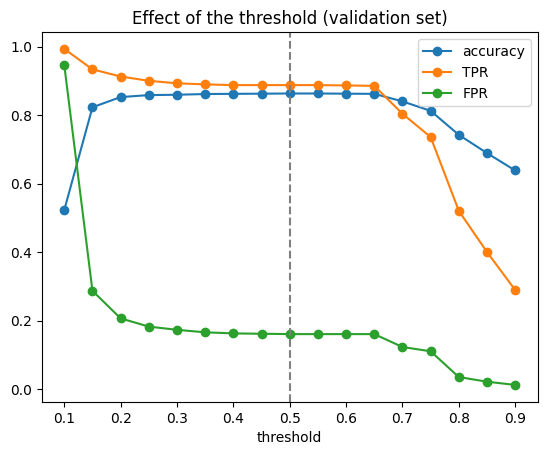

,threshold,accuracy,TPR,FPR
0,0.10,0.523,0.994,0.947
1,0.15,0.823,0.934,0.287
2,0.20,0.853,0.913,0.207
3,0.25,0.859,0.901,0.183
4,0.30,0.860,0.893,0.173
5,0.35,0.862,0.890,0.166
6,0.40,0.863,0.888,0.163
7,0.45,0.863,0.888,0.162
8,0.50,0.864,0.888,0.161
9,0.55,0.864,0.888,0.161


In [13]:
val_prob = final_model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.1, 0.95, 0.05)

rows = []
for t in thresholds:
    pred = (val_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred).ravel()
    rows.append([t, accuracy_score(y_val, pred), tp / (tp + fn), fp / (fp + tn)])
thr = pd.DataFrame(rows, columns=['threshold', 'accuracy', 'TPR', 'FPR'])

thr.plot(x='threshold', y=['accuracy', 'TPR', 'FPR'], marker='o')
plt.axvline(0.5, color='grey', linestyle='--')
plt.title('Effect of the threshold (validation set)')
plt.show()
thr.round(3)

The accuracy is almost the same for every threshold between ~0.35 and ~0.65, because most predicted probabilities are either quite low or quite high (mainly because of the binary 'same community' feature). So changing the threshold does not really improve the model and we keep the default threshold of 0.5.

'Same community' and Adamic-Adar have the largest coefficients, followed by preferential attachment. 'Same attribute' has a small positive coefficient. Common neighbours gets a negative coefficient, even though links have much more common neighbours on average (see Section 2). This is probably because common neighbours and Adamic-Adar are strongly correlated (both count shared neighbours), so the model mainly uses Adamic-Adar and the coefficient of common neighbours corrects for that. So the coefficients of these correlated features should not be interpreted one by one. Jaccard is close to 0 for the same reason.

## 5. Final results (test set)

Accuracy:  0.859
Precision: 0.845
TPR:       0.880
F1:        0.862
AUC:       0.909


/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  

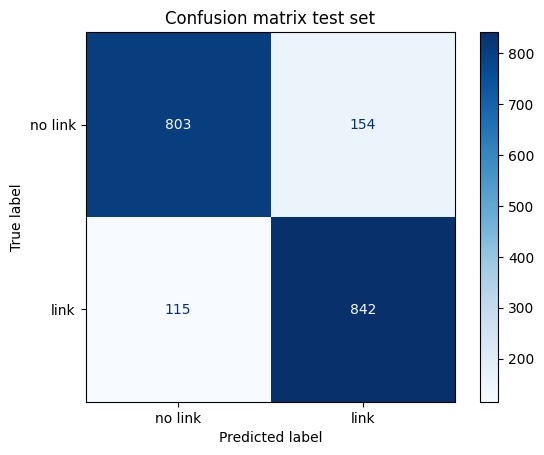

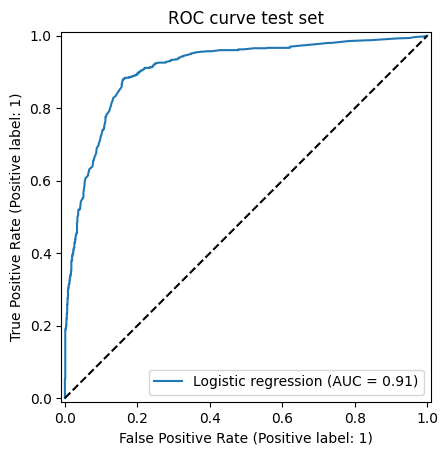

In [14]:
y_pred = final_model.predict(X_test)
y_prob = final_model.predict_proba(X_test)[:, 1]

print('Accuracy:  %0.3f' % accuracy_score(y_test, y_pred))
print('Precision: %0.3f' % precision_score(y_test, y_pred))
print('TPR:       %0.3f' % recall_score(y_test, y_pred))
print('F1:        %0.3f' % f1_score(y_test, y_pred))
print('AUC:       %0.3f' % roc_auc_score(y_test, y_prob))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=['no link', 'link']).plot(cmap='Blues')
plt.title('Confusion matrix test set')
plt.show()

RocCurveDisplay.from_predictions(y_test, y_prob, name='Logistic regression')
plt.plot([0, 1], [0, 1], 'k--')
plt.title('ROC curve test set')
plt.show()

### 5.1 Performance per group

To support the ethics part we also look at the performance per attribute group. A link has two nodes, so we count a pair for every group of its two nodes (a pair between a node of group a and a node of group c counts for both a and c). Because of this the groups overlap, so the overall row is not simply the average of the groups.

We also split the test pairs into same-group pairs and mixed-group pairs.

In [15]:
res = test[['u', 'v', 'label']].copy()
res['pred'] = y_pred
res['group_u'] = res['u'].map(attr)
res['group_v'] = res['v'].map(attr)

def group_metrics(d):
    tp = ((d.label == 1) & (d.pred == 1)).sum()
    fn = ((d.label == 1) & (d.pred == 0)).sum()
    fp = ((d.label == 0) & (d.pred == 1)).sum()
    tn = ((d.label == 0) & (d.pred == 0)).sum()
    return {'n pairs': len(d),
            'accuracy': (tp + tn) / len(d),
            'TPR (recall)': tp / (tp + fn),
            'FPR': fp / (fp + tn),
            'precision': tp / (tp + fp),
            'P(predicted link)': d.pred.mean(),
            'P(true link)': d.label.mean()}

per_group = {}
for g in groups:
    per_group[g] = group_metrics(res[(res.group_u == g) | (res.group_v == g)])
per_group['all'] = group_metrics(res)
per_group = pd.DataFrame(per_group).T
per_group.round(3)

,n pairs,accuracy,TPR (recall),FPR,precision,P(predicted link),P(true link)
a,496.0,0.827,0.777,0.138,0.800,0.403,0.415
b,571.0,0.844,0.802,0.123,0.832,0.417,0.433
c,530.0,0.872,0.866,0.123,0.866,0.477,0.477
d,523.0,0.887,0.902,0.125,0.855,0.474,0.449
e,527.0,0.865,0.862,0.132,0.828,0.442,0.425
f,517.0,0.896,0.932,0.131,0.840,0.470,0.424
all,1914.0,0.859,0.880,0.161,0.845,0.520,0.500


In [16]:
# same-group vs mixed-group pairs
same = res[res.group_u == res.group_v]
mixed = res[res.group_u != res.group_v]
pair_type = pd.DataFrame({'same group': group_metrics(same), 'mixed groups': group_metrics(mixed)}).T
pair_type.round(3)

,n pairs,accuracy,TPR (recall),FPR,precision,P(predicted link),P(true link)
same group,664.0,0.833,0.940,0.590,0.863,0.869,0.798
mixed groups,1250.0,0.874,0.806,0.091,0.821,0.335,0.342


In [17]:
# same-group pairs, split per group
same_per_group = {}
for g in groups:
    same_per_group[g] = group_metrics(same[same.group_u == g])
pd.DataFrame(same_per_group).T.round(3)

,n pairs,accuracy,TPR (recall),FPR,precision,P(predicted link),P(true link)
a,103.0,0.767,0.866,0.619,0.845,0.816,0.796
b,125.0,0.800,0.898,0.556,0.854,0.824,0.784
c,122.0,0.877,0.934,0.500,0.925,0.877,0.869
d,100.0,0.890,0.988,0.588,0.891,0.920,0.830
e,105.0,0.819,0.974,0.630,0.817,0.886,0.743
f,109.0,0.844,0.988,0.615,0.837,0.899,0.761


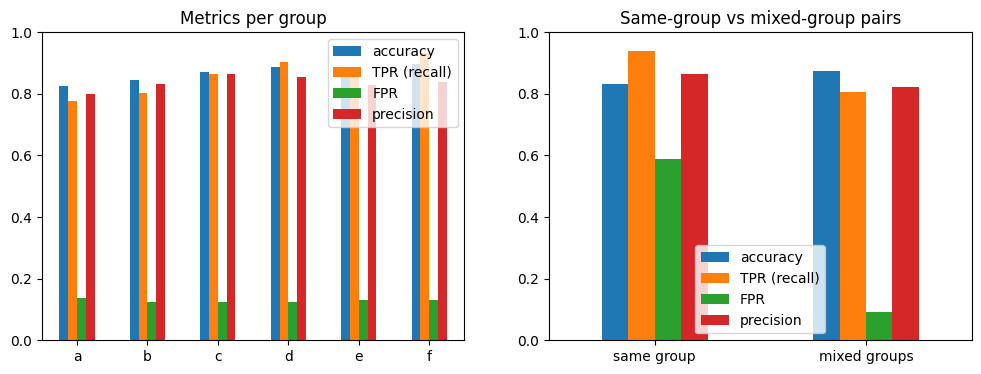

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
per_group.drop('all')[['accuracy', 'TPR (recall)', 'FPR', 'precision']].plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Metrics per group')
pair_type[['accuracy', 'TPR (recall)', 'FPR', 'precision']].plot.bar(ax=ax[1], rot=0)
ax[1].set_title('Same-group vs mixed-group pairs')
for a in ax:
    a.set_ylim(0, 1)
plt.show()

### 5.2 Prediction distribution per group

How often is each group part of a predicted link, compared to how often it is part of a true link (counted per node of the link)?

In [19]:
def share_per_group(d):
    nodes = pd.concat([d.group_u, d.group_v])
    return nodes.value_counts(normalize=True).reindex(groups)

pd.DataFrame({'share in predicted links': share_per_group(res[res.pred == 1]),
              'share in true links': share_per_group(res[res.label == 1]),
              'share of all nodes': group_counts / N}).round(3)

,share in predicted links,share in true links,share of all nodes
a,0.143,0.150,0.167
b,0.171,0.180,0.167
c,0.181,0.188,0.167
d,0.171,0.166,0.167
e,0.164,0.158,0.167
f,0.171,0.158,0.167


### 5.3 Communities vs. attribute

The 'same community' feature does not use the attribute directly, but if the communities are mostly made up of one group it can still work as a proxy for the attribute. We check this on the full visible network.

In [20]:
comm_full = get_communities(G)
table = pd.crosstab(pd.Series(comm_full, name='community'), attributes)
print(table)

print('\nShare of the largest group in each community:')
print((table.max(axis=1) / table.sum(axis=1)).round(2))

attribute    a    b    c    d    e    f
community                              
0           15  226   20   18   19    8
1           13   20   15   19  220   16
2           16   17   13  220   14   21
3            9   16  221   15   20   18
4           14   11   19   13   17  225
5          233   10   12   15   10   12

Share of the largest group in each community:
community
0    0.74
1    0.73
2    0.73
3    0.74
4    0.75
5    0.80
dtype: float64


## 6. Limitations (notes for the report)

- The negative examples are random pairs that are not in the visible network. A few of them could actually be one of the ~700 removed links, but with ~1.6 million possible pairs this chance is very small.
- Our training features are computed on a network with an extra 10% of the edges removed, so the training network is a bit sparser than the network we use for the final predictions. This could explain why the model predicts slightly more than 50% of the links in `solutionInput.csv` as existing.
- The results are based on one random split and one run of the community detection (which can give slightly different communities).
- The features only use the local structure (common neighbours) and the communities, nodes with few or no visible links are hard to predict.

## 7. Predictions for solutionInput.csv

For the final predictions the model is trained again on the training + validation data. The features of the input links are computed on the full visible network (the input links are not in this network, so this is the same situation as in our training data).

In [21]:
final_model.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

inputLinks = pd.read_csv('input/solutionInput.csv', index_col='ID')
X_input = getFeatures(G, inputLinks[['int1', 'int2']].values, comm_full)[FEATURES]
predictions = final_model.predict(X_input)

pd.DataFrame(predictions, index=inputLinks.index).to_csv('predictions.csv', index=True, header=['Prediction'], index_label='ID')
print('Number of predicted links: %d out of %d' % (predictions.sum(), len(predictions)))

Number of predicted links: 773 out of 1416


/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/lab1/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/narekmoradian/UvA/Funs/labs/

In [22]:
# prediction for a single edge given as input
i, j = 164, 1010
print('Prediction for edge (%d, %d):' % (i, j), final_model.predict(getFeature(G, i, j, comm_full))[0])

Prediction for edge (164, 1010): 1
